<a href="https://colab.research.google.com/github/luisferdm6/03-china-mexico-trade-audit/blob/main/01_china_mexico_trade_asymmetry_audit.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Bilateral Trade Asymmetries & Customs Risk Audit: China – Mexico
### Mirror Trade Statistics Analysis for Tariff Gap and Undervaluation Detection

**Analyst:** Luis Fernando Duardo Medina  
**Methodology:** Mirror Trade Statistics (UN Comtrade / WCO)  
**Tech Stack:** DuckDB (SQL), Pandas, Seaborn, Matplotlib

In [39]:
import duckdb
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib import ticker

In [40]:
df = pd.read_csv("comtrade_china_mexico.csv", index_col=False)

print(f"Dataset dimensions: {df.shape}")

df.head()

Dataset dimensions: (18, 47)


,typeCode,freqCode,refPeriodId,refYear,refMonth,period,reporterCode,reporterISO,reporterDesc,flowCode,...,netWgt,isNetWgtEstimated,grossWgt,isGrossWgtEstimated,cifvalue,fobvalue,primaryValue,legacyEstimationFlag,isReported,isAggregate
0,C,A,20230101,2023,52,2023,484,MEX,Mexico,M,...,0,True,0,False,NaN,765147704,765147704,4,False,True
1,C,A,20230101,2023,52,2023,484,MEX,Mexico,M,...,0,True,0,False,NaN,21701094738,21701094738,4,False,True
2,C,A,20230101,2023,52,2023,484,MEX,Mexico,M,...,0,True,0,False,NaN,39829628491,39829628491,4,False,True
3,C,A,20230101,2023,52,2023,484,MEX,Mexico,X,...,0,True,0,False,NaN,983645,983645,4,False,True
4,C,A,20230101,2023,52,2023,484,MEX,Mexico,X,...,0,True,0,False,NaN,551449072,551449072,4,False,True


In [41]:
df_limpio = df[['refYear', 'flowDesc', 'cmdCode', 'primaryValue']]

df_limpio.head()

,refYear,flowDesc,cmdCode,primaryValue
0,2023,Import,64,765147704
1,2023,Import,84,21701094738
2,2023,Import,85,39829628491
3,2023,Export,64,983645
4,2023,Export,84,551449072


In [42]:
consulta = duckdb.sql("""
SELECT
  flowDesc AS flujo,
  SUM(primaryValue) AS valor_total_usd
FROM df_limpio
GROUP BY flowDesc
""").df()

consulta

,flujo,valor_total_usd
0,Import,2.035462e+11
1,Export,4.515367e+09


In [43]:
consulta_capitulos = duckdb.sql("""
SELECT
  cmdCode AS capitulo,
  flowDesc AS flujo,
  SUM(primaryValue) AS total_usd
FROM df_limpio
GROUP BY cmdCode, flowDesc
ORDER BY cmdCode ASC, SUM(primaryValue) DESC
""").df()

consulta_capitulos

,capitulo,flujo,total_usd
0,64,Import,2.269195e+09
1,64,Export,1.708209e+06
2,84,Import,7.370048e+10
3,84,Export,1.506250e+09
4,85,Import,1.275765e+11
5,85,Export,3.007409e+09


In [44]:
consulta_balanza = duckdb.sql("""
SELECT
  cmdCode AS capitulo,
  SUM(CASE WHEN flowDesc = 'Import' THEN primaryValue ELSE 0 END) AS importaciones_usd,
  SUM(CASE WHEN flowDesc = 'Export' THEN primaryValue ELSE 0 END) AS exportaciones_usd,
  exportaciones_usd - importaciones_usd AS balanza_comercial_usd
FROM df_limpio
GROUP BY cmdCode
ORDER BY capitulo ASC
""").df()

consulta_balanza


,capitulo,importaciones_usd,exportaciones_usd,balanza_comercial_usd
0,64,2.269195e+09,1.708209e+06,-2.267487e+09
1,84,7.370048e+10,1.506250e+09,-7.219423e+10
2,85,1.275765e+11,3.007409e+09,-1.245691e+11


In [45]:
balanza_anual = duckdb.sql("""
SELECT
  cmdCode AS capitulo,
  refYear AS año,
  SUM(CASE WHEN flowDesc = 'Import' THEN primaryValue ELSE 0 END) AS importaciones_usd,
  SUM(CASE WHEN flowDesc = 'Export' THEN primaryValue ELSE 0 END) AS exportaciones_usd,
  exportaciones_usd - importaciones_usd AS balanza_comercial_usd
FROM df_limpio
GROUP BY cmdCode, refYear
ORDER BY capitulo ASC, año ASC
""").df()

balanza_anual

,capitulo,año,importaciones_usd,exportaciones_usd,balanza_comercial_usd
0,64,2023,7.651477e+08,9.836450e+05,-7.641641e+08
1,64,2024,8.972727e+08,5.431690e+05,-8.967295e+08
2,64,2025,6.067750e+08,1.813950e+05,-6.065936e+08
3,84,2023,2.170109e+10,5.514491e+08,-2.114965e+10
4,84,2024,2.535762e+10,4.989269e+08,-2.485869e+10
5,84,2025,2.664177e+10,4.558735e+08,-2.618589e+10
6,85,2023,3.982963e+10,1.070976e+09,-3.875865e+10
7,85,2024,4.277251e+10,9.650949e+08,-4.180742e+10
8,85,2025,4.497440e+10,9.713383e+08,-4.400306e+10


In [46]:
balanza_anual['ratio_asimetria'] = balanza_anual['importaciones_usd'] / balanza_anual['exportaciones_usd']

balanza_anual

,capitulo,año,importaciones_usd,exportaciones_usd,balanza_comercial_usd,ratio_asimetria
0,64,2023,7.651477e+08,9.836450e+05,-7.641641e+08,777.869764
1,64,2024,8.972727e+08,5.431690e+05,-8.967295e+08,1651.921708
2,64,2025,6.067750e+08,1.813950e+05,-6.065936e+08,3345.048144
3,84,2023,2.170109e+10,5.514491e+08,-2.114965e+10,39.352854
4,84,2024,2.535762e+10,4.989269e+08,-2.485869e+10,50.824312
5,84,2025,2.664177e+10,4.558735e+08,-2.618589e+10,58.441137
6,85,2023,3.982963e+10,1.070976e+09,-3.875865e+10,37.190022
7,85,2024,4.277251e+10,9.650949e+08,-4.180742e+10,44.319489
8,85,2025,4.497440e+10,9.713383e+08,-4.400306e+10,46.301481


In [47]:
balanza_anual = balanza_anual.sort_values(by='ratio_asimetria', ascending=False)

balanza_anual.head()

,capitulo,año,importaciones_usd,exportaciones_usd,balanza_comercial_usd,ratio_asimetria
2,64,2025,6.067750e+08,181395.0,-6.065936e+08,3345.048144
1,64,2024,8.972727e+08,543169.0,-8.967295e+08,1651.921708
0,64,2023,7.651477e+08,983645.0,-7.641641e+08,777.869764
5,84,2025,2.664177e+10,455873537.0,-2.618589e+10,58.441137
4,84,2024,2.535762e+10,498926899.0,-2.485869e+10,50.824312


In [48]:
balanza_anual = balanza_anual.sort_values(by='balanza_comercial_usd', ascending=True)

balanza_anual.head()

,capitulo,año,importaciones_usd,exportaciones_usd,balanza_comercial_usd,ratio_asimetria
8,85,2025,4.497440e+10,9.713383e+08,-4.400306e+10,46.301481
7,85,2024,4.277251e+10,9.650949e+08,-4.180742e+10,44.319489
6,85,2023,3.982963e+10,1.070976e+09,-3.875865e+10,37.190022
5,84,2025,2.664177e+10,4.558735e+08,-2.618589e+10,58.441137
4,84,2024,2.535762e+10,4.989269e+08,-2.485869e+10,50.824312


In [49]:
df_reporte = balanza_anual.copy()

df_reporte['deficit_b_usd'] = (df_reporte['balanza_comercial_usd'] / 1e9).round(2)
df_reporte['ratio_asimetria'] = df_reporte['ratio_asimetria'].round(1)
df_reporte['deficit_b_usd'] = df_reporte['deficit_b_usd'].map(lambda x: f"-${abs(x):.2f} B" if x < 0 else f"${x:.2f} B")

df_reporte.to_csv("auditoria_china_mexico_resumen.csv", index=False)

df_reporte[['capitulo', 'año', 'deficit_b_usd', 'ratio_asimetria']].head()

,capitulo,año,deficit_b_usd,ratio_asimetria
8,85,2025,-$44.00 B,46.3
7,85,2024,-$41.81 B,44.3
6,85,2023,-$38.76 B,37.2
5,84,2025,-$26.19 B,58.4
4,84,2024,-$24.86 B,50.8


In [50]:
import matplotlib.pyplot as plt

df_cap85 = balanza_anual[balanza_anual['capitulo'] == 85]

df_cap85

,capitulo,año,importaciones_usd,exportaciones_usd,balanza_comercial_usd,ratio_asimetria
8,85,2025,4.497440e+10,9.713383e+08,-4.400306e+10,46.301481
7,85,2024,4.277251e+10,9.650949e+08,-4.180742e+10,44.319489
6,85,2023,3.982963e+10,1.070976e+09,-3.875865e+10,37.190022


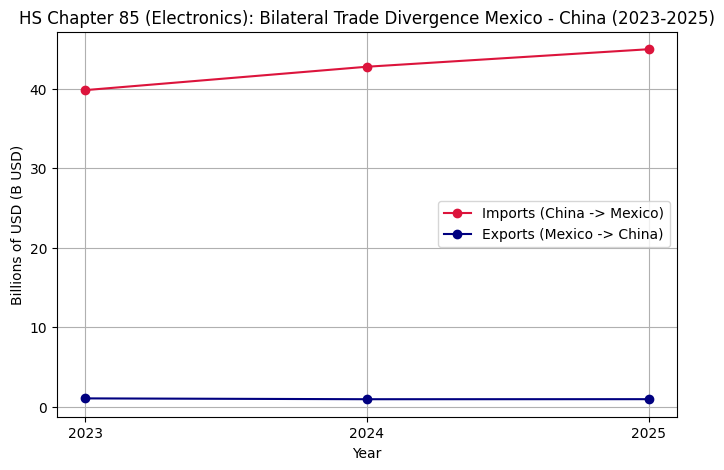

In [51]:
df_cap85 = df_cap85.sort_values(by='año')

plt.figure(figsize=(8, 5))
plt.plot(df_cap85['año'], df_cap85['importaciones_usd'] / 1e9, label='Imports (China -> Mexico)', marker='o', color='crimson')
plt.plot(df_cap85['año'], df_cap85['exportaciones_usd'] / 1e9, label='Exports (Mexico -> China)', marker='o', color='navy')
plt.title('HS Chapter 85 (Electronics): Bilateral Trade Divergence Mexico - China (2023-2025)')
plt.xlabel('Year')
plt.ylabel('Billions of USD (B USD)')
plt.xticks([2023, 2024, 2025])
plt.legend()
plt.grid(True)
plt.show()

In [52]:
CATALOGO_ARANCELARIO = {
    1: 'Live animals',
    2: 'Meat and edible meat offal',
    3: 'Fish and crustaceans, molluscs and other aquatic invertebrates',
    4: 'Dairy produce; birds eggs; natural honey',
    5: 'Products of animal origin, not elsewhere specified',
    6: 'Live trees and other plants; bulbs, roots and the like',
    7: 'Edible vegetables and certain roots and tubers',
    8: 'Edible fruit and nuts; peel of citrus fruit or melons',
    9: 'Coffee, tea, mate and spices',
    10: 'Cereals',
    11: 'Products of the milling industry; malt; starches',
    12: 'Oil seeds and oleaginous fruits; industrial or medicinal plants',
    13: 'Lac; gums, resins and other vegetable saps and extracts',
    14: 'Vegetable plaiting materials; vegetable products not elsewhere specified',
    15: 'Animal or vegetable fats and oils and their cleavage products',
    16: 'Preparations of meat, of fish or of crustaceans',
    17: 'Sugars and sugar confectionery',
    18: 'Cocoa and cocoa preparations',
    19: 'Preparations of cereals, flour, starch or milk; pastrycooks products',
    20: 'Preparations of vegetables, fruit, nuts or other parts of plants',
    21: 'Miscellaneous edible preparations',
    22: 'Beverages, spirits and vinegar',
    23: 'Residues and waste from the food industries; prepared animal fodder',
    24: 'Tobacco and manufactured tobacco substitutes',
    25: 'Salt; sulphur; earths and stone; plastering materials, lime and cement',
    26: 'Ores, slag and ash',
    27: 'Mineral fuels, mineral oils and products of their distillation',
    28: 'Inorganic chemicals; organic or inorganic compounds of precious metals',
    29: 'Organic chemicals',
    30: 'Pharmaceutical products',
    31: 'Fertilisers',
    32: 'Tanning or dyeing extracts; tannins and their derivatives; pigments',
    33: 'Essential oils and resinoids; perfumery, cosmetic or toilet preparations',
    34: 'Soap, organic surface-active agents, washing preparations, waxes',
    35: 'Albuminoidal substances; modified starches; glues; enzymes',
    36: 'Explosives; pyrotechnic products; matches; pyrophoric alloys',
    37: 'Photographic or cinematographic goods',
    38: 'Miscellaneous chemical products',
    39: 'Plastics and articles thereof',
    40: 'Rubber and articles thereof',
    41: 'Raw hides and skins (other than furskins) and leather',
    42: 'Articles of leather; saddlery and harness; travel goods, handbags',
    43: 'Furskins and artificial fur; manufactures thereof',
    44: 'Wood and articles of wood; wood charcoal',
    45: 'Cork and articles of cork',
    46: 'Manufactures of straw, of esparto or of other plaiting materials',
    47: 'Pulp of wood or of other fibrous cellulosic material; recovered paper',
    48: 'Paper and paperboard; articles of paper pulp, of paper or of paperboard',
    49: 'Printed books, newspapers, pictures and other products of the printing industry',
    50: 'Silk',
    51: 'Wool, fine or coarse animal hair; horsehair yarn and woven fabric',
    52: 'Cotton',
    53: 'Other vegetable textile fibres; paper yarn and woven fabrics of paper yarn',
    54: 'Man-made filaments; strip and the like of man-made textile materials',
    55: 'Man-made staple fibres',
    56: 'Wadding, felt and nonwovens; special yarns; twine, cordage, ropes',
    57: 'Carpets and other textile floor coverings',
    58: 'Special woven fabrics; tufted textile fabrics; lace; tapestries',
    59: 'Impregnated, coated, covered or laminated textile fabrics',
    60: 'Knitted or crocheted fabrics',
    61: 'Articles of apparel and clothing accessories, knitted or crocheted',
    62: 'Articles of apparel and clothing accessories, not knitted or crocheted',
    63: 'Other made up textile articles; sets; worn clothing and worn textile articles',
    64: 'Footwear, gaiters and the like; parts of such articles',
    65: 'Headgear and parts thereof',
    66: 'Umbrellas, sun umbrellas, walking-sticks, seat-sticks, whips',
    67: 'Prepared feathers and down and articles made of feathers or of down',
    68: 'Articles of stone, plaster, cement, asbestos, mica or similar materials',
    69: 'Ceramic products',
    70: 'Glass and glassware',
    71: 'Natural or cultured pearls, precious or semi-precious stones, precious metals',
    72: 'Iron and steel',
    73: 'Articles of iron or steel',
    74: 'Copper and articles thereof',
    75: 'Nickel and articles thereof',
    76: 'Aluminium and articles thereof',
    78: 'Lead and articles thereof',
    79: 'Zinc and articles thereof',
    80: 'Tin and articles thereof',
    81: 'Other base metals; cermets; articles thereof',
    82: 'Tools, implements, cutlery, spoons and forks, of base metal',
    83: 'Miscellaneous articles of base metal',
    84: 'Nuclear reactors, boilers, machinery and mechanical appliances; parts thereof',
    85: 'Electrical machinery and equipment and parts thereof; electronics',
    86: 'Railway or tramway locomotives, rolling-stock and parts thereof',
    87: 'Vehicles other than railway or tramway rolling-stock, and parts',
    88: 'Aircraft, spacecraft, and parts thereof',
    89: 'Ships, boats and floating structures',
    90: 'Optical, photographic, cinematographic, measuring, medical instruments',
    91: 'Clocks and watches and parts thereof',
    92: 'Musical instruments; parts and accessories of such articles',
    93: 'Arms and ammunition; parts and accessories thereof',
    94: 'Furniture; bedding, mattresses; lamps and lighting fittings',
    95: 'Toys, games and sports requisites; parts and accessories thereof',
    96: 'Miscellaneous manufactured articles',
    97: 'Works of art, collectors pieces and antiques'
}

In [53]:
def calcular_metricas_comerciales(df: pd.DataFrame, capitulo: int) -> pd.DataFrame:

  if capitulo not in df['capitulo'].values:
    print(f"DATA ERROR: Chapter {capitulo} does not exist in dataset. Available chapters: {sorted(df['capitulo'].unique().tolist())}")
    return pd.DataFrame()

  datos = df[df['capitulo'] == capitulo].copy()
  datos['tasa_cobertura_pct'] = (datos['exportaciones_usd'] / datos['importaciones_usd'] * 100).round(2)
  datos['indice_balanza_normalizada'] = ((datos['exportaciones_usd'] - datos['importaciones_usd']) / (datos['exportaciones_usd'] + datos['importaciones_usd'])).round(4)
  datos = datos.sort_values('año').reset_index(drop=True)

  return datos

In [54]:
def generar_resumen_ejecutivo(df: pd.DataFrame) -> pd.DataFrame:

  columnas_requeridas = {'capitulo', 'importaciones_usd', 'exportaciones_usd'}
  if not columnas_requeridas.issubset(df.columns):
    columnas_faltantes = columnas_requeridas - set(df.columns)
    print(f"SCHEMA ERROR: Missing required columns: {columnas_faltantes}")
    return pd.DataFrame()

  resumen = df.groupby('capitulo')[['importaciones_usd', 'exportaciones_usd']].sum().reset_index()
  resumen['balanza_comercial_usd'] = (resumen['exportaciones_usd'] - resumen['importaciones_usd'])
  resumen['indice_balanza_normalizada'] = (resumen['balanza_comercial_usd'] / (resumen['exportaciones_usd'] + resumen['importaciones_usd'])).round(4)
  resumen = resumen.sort_values('balanza_comercial_usd').reset_index(drop=True)

  return resumen

In [55]:
def graficar_divergencia(
    df: pd.DataFrame,
    capitulo: int,
    pais_local: str,
    socio: str,
    catalogo: dict[int, str] = CATALOGO_ARANCELARIO
    ) -> None:

    """
    Visualize bilateral trade divergence for a Harmonized System (HS) tariff chapter.

    Dynamically computes symmetric monetary scaling (millions or billions of USD),
    evaluates cumulative trade balance (surplus or deficit), and plots temporal flow
    divergence with conditional shading.

    Args:
        df (pd.DataFrame): Table containing 'capitulo', 'año', 'importaciones_usd', and 'exportaciones_usd'.
        capitulo (int): 2-digit HS tariff chapter code (e.g., 85 for electronics).
        pais_local (str): Focal reporting country name (e.g., 'Mexico').
        socio (str): Counterpart partner country name (e.g., 'China').
        catalogo (dict[int, str], optional): Official HS chapter descriptions dictionary.
            Defaults to CATALOGO_ARANCELARIO.

    Returns:
        None: Displays a Matplotlib figure.
    """

    if not isinstance(df, pd.DataFrame):
        print("INPUT ERROR: Argument 'df' must be a Pandas DataFrame.")
        return

    if not isinstance(pais_local, str) or not isinstance(socio, str):
        print("INPUT ERROR: 'pais_local' and 'socio' must be strings (e.g., 'Mexico', 'China').")
        return

    columnas_obligatorias = {'capitulo', 'año', 'importaciones_usd', 'exportaciones_usd'}
    if not columnas_obligatorias.issubset(df.columns):
        print("SCHEMA ERROR: Table is missing required columns (capitulo, año, importaciones_usd, exportaciones_usd).")
        return

    if not isinstance(capitulo, int):
        print("INPUT ERROR: Chapter must be an integer without quotes (e.g., 85, not '85').")
        return

    if capitulo not in df['capitulo'].values:
        print(f"DATA ERROR: Chapter {capitulo} does not exist in dataset. Available chapters: {sorted(df['capitulo'].unique().tolist())}")
        return

    descripcion = f" ({catalogo.get(capitulo)})" if catalogo and capitulo in catalogo else ""

    datos = df[df['capitulo'] == capitulo].sort_values('año')

    en_millones = max(datos['importaciones_usd'].max(), datos['exportaciones_usd'].max()) < 1e9
    divisor = 1e6 if en_millones else 1e9
    unidad = 'M USD' if en_millones else 'B USD'

    es_superavit = datos['exportaciones_usd'].sum() >= datos['importaciones_usd'].sum()
    color_balance = 'forestgreen' if es_superavit else 'crimson'
    etiqueta_balance = 'Trade Surplus' if es_superavit else 'Trade Deficit'

    plt.figure(figsize=(8, 5))
    plt.plot(datos['año'], datos['importaciones_usd'] / divisor, label=f"Imports ({socio} -> {pais_local})", marker='o', color='crimson')
    plt.plot(datos['año'], datos['exportaciones_usd'] / divisor, label=f"Exports ({pais_local} -> {socio})", marker='o', color='navy')
    plt.fill_between(datos['año'], datos['exportaciones_usd'] / divisor, datos['importaciones_usd'] / divisor, color=color_balance, alpha=0.15, label=etiqueta_balance)
    plt.title(f"HS Chapter {capitulo}{descripcion}: Trade Divergence {pais_local} - {socio} ({datos['año'].min()}-{datos['año'].max()})")
    plt.xlabel('Year')
    plt.ylabel(f'Trade Value ({unidad})')
    plt.xticks(datos['año'].unique())
    plt.legend()
    plt.grid(True)
    plt.show()

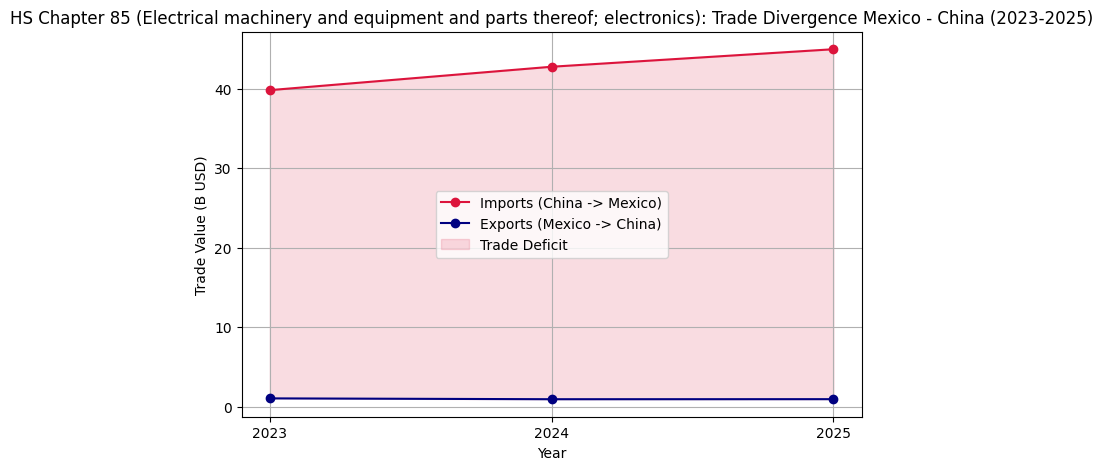

In [56]:
graficar_divergencia(balanza_anual, 85, 'Mexico', 'China')

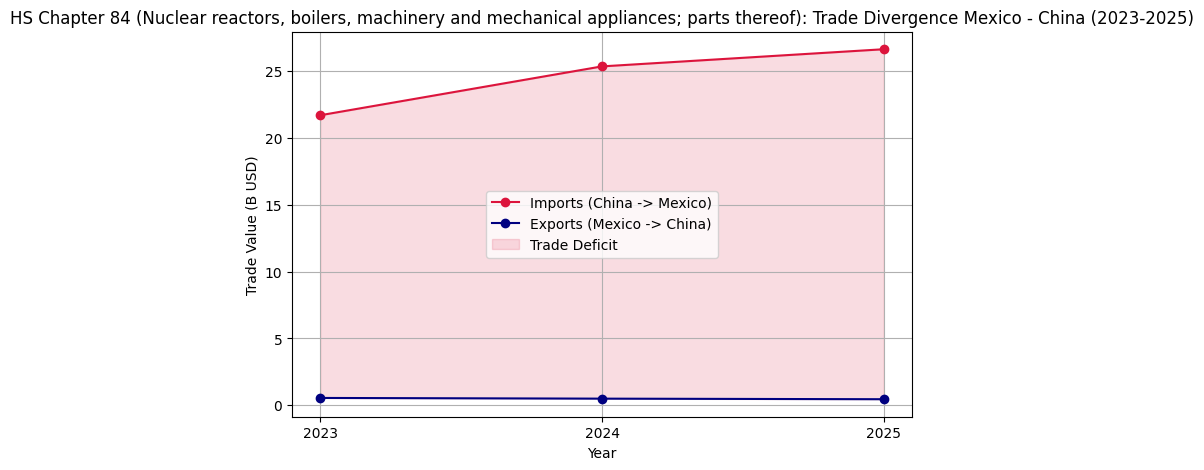

In [57]:
graficar_divergencia(balanza_anual, 84, 'Mexico', 'China')

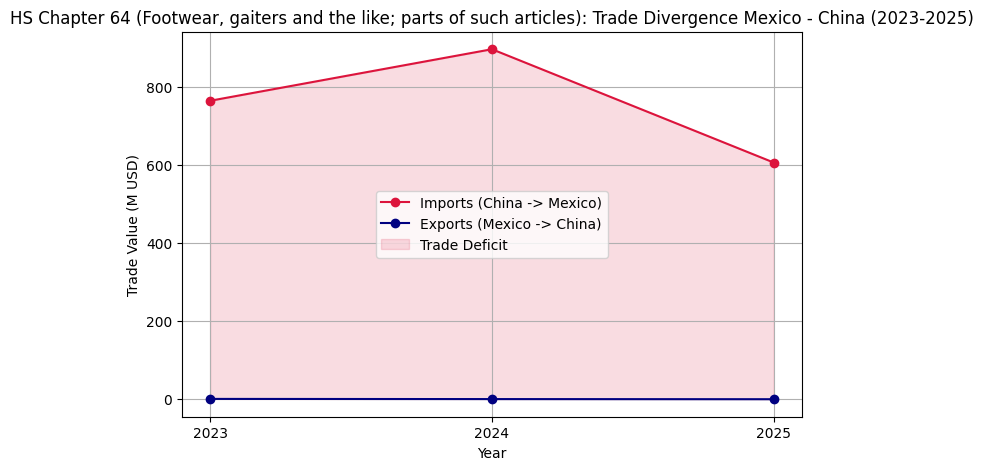

In [58]:
graficar_divergencia(balanza_anual, 64, 'Mexico', 'China')

In [59]:
graficar_divergencia(balanza_anual, '84', 'Mexico', 'China')

ERROR DE ENTRADA: El capítulo debe de ser un número entero sin comillas (ej. 85, no '85').


In [60]:
graficar_divergencia(balanza_anual, 10, 'Mexico', 'China')

ERROR DE DATOS: El capítulo 10 no existe en la base. Capítulos disponibles: [64, 84, 85]


In [61]:
graficar_divergencia(balanza_anual[['año', 'capitulo', 'importaciones_usd']], 84, 'Mexico', 'China')

ERROR DE ESTRUCTURA: La tabla no contiene las columnas requeridas (capitulo, año, importaciones_usd, exportaciones_usd).


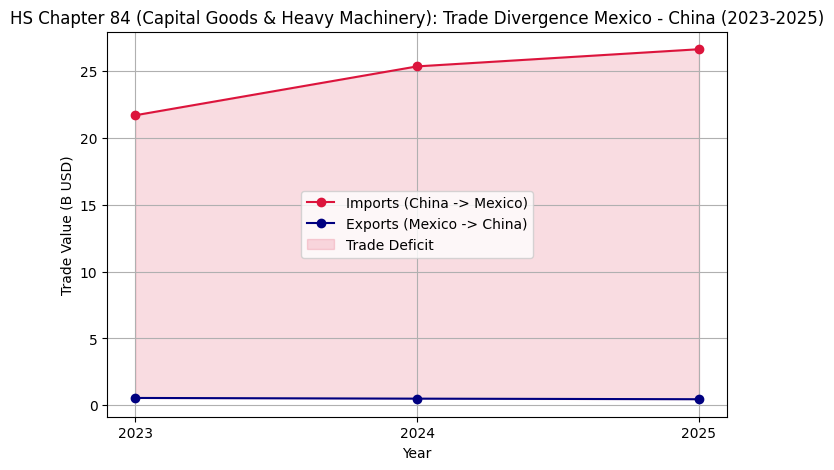

In [62]:
graficar_divergencia(balanza_anual, 84, 'Mexico', 'China', catalogo={84: 'Capital Goods & Heavy Machinery'})

In [63]:
help(graficar_divergencia)

Help on function graficar_divergencia in module __main__:

graficar_divergencia(
    df: pandas.core.frame.DataFrame,
    capitulo: int,
    pais_local: str,
    socio: str,
    catalogo: dict[int, str] = {1: 'Animales vivos', 2: 'Carne y despojos comestibles', 3: 'Pescados, crustáceos y moluscos', 4: 'Leche, productos lácteos, huevos y miel', 5: 'Demás productos de origen animal', 6: 'Plantas vivas y floricultura', 7: 'Hortalizas, plantas, raíces y tubérculos', 8: 'Frutas y frutos comestibles', 9: 'Café, té, yerba mate y especias', 10: 'Cereales', 11: 'Productos de la molienda; malta; almidón', 12: 'Semillas y frutos oleaginosos; plantas industriales', 13: 'Gomas, resinas y jugos vegetales', 14: 'Materias trenzables y productos de origen vegetal', 15: 'Grasas y aceites animales o vegetales', 16: 'Preparaciones de carne, pescado o crustáceos', 17: 'Azúcares y confitería', 18: 'Cacao y sus preparaciones', 19: 'Preparaciones a base de cereales, harina o leche', 20: 'Preparaciones de hort

In [64]:
calcular_metricas_comerciales(balanza_anual, 85)

,capitulo,año,importaciones_usd,exportaciones_usd,balanza_comercial_usd,ratio_asimetria,tasa_cobertura_pct,indice_balanza_normalizada
0,85,2023,3.982963e+10,1.070976e+09,-3.875865e+10,37.190022,2.69,-0.9476
1,85,2024,4.277251e+10,9.650949e+08,-4.180742e+10,44.319489,2.26,-0.9559
2,85,2025,4.497440e+10,9.713383e+08,-4.400306e+10,46.301481,2.16,-0.9577


In [65]:
calcular_metricas_comerciales(balanza_anual, 99)

ERROR DE DATOS: El capítulo 99 no existe en la base. Capítulos disponibles: [64, 84, 85]


""


In [66]:
generar_resumen_ejecutivo(balanza_anual)

,capitulo,importaciones_usd,exportaciones_usd,balanza_comercial_usd,indice_balanza_normalizada
0,85,1.275765e+11,3.007409e+09,-1.245691e+11,-0.9539
1,84,7.370048e+10,1.506250e+09,-7.219423e+10,-0.9599
2,64,2.269195e+09,1.708209e+06,-2.267487e+09,-0.9985


In [67]:
trade_data = balanza_anual.rename(columns={
    'capitulo': 'chapter',
    'año': 'year',
    'importaciones_usd': 'imports_usd',
    'exportaciones_usd': 'exports_usd',
    'balanza_comercial_usd': 'trade_balance_usd',
    'ratio_asimetria': 'asymmetry_ratio'
})

In [68]:
trade_data.head()

,chapter,year,imports_usd,exports_usd,trade_balance_usd,asymmetry_ratio
8,85,2025,4.497440e+10,9.713383e+08,-4.400306e+10,46.301481
7,85,2024,4.277251e+10,9.650949e+08,-4.180742e+10,44.319489
6,85,2023,3.982963e+10,1.070976e+09,-3.875865e+10,37.190022
5,84,2025,2.664177e+10,4.558735e+08,-2.618589e+10,58.441137
4,84,2024,2.535762e+10,4.989269e+08,-2.485869e+10,50.824312


In [69]:
def generate_executive_summary(df: pd.DataFrame) -> pd.DataFrame:
    """Aggregate multi-year trade volume and rank chapters by absolute deficit."""
    required_cols = {'chapter', 'imports_usd', 'exports_usd'}
    if not required_cols.issubset(df.columns):
        missing = required_cols - set(df.columns)
        print(f"SCHEMA ERROR: Missing required columns: {missing}")
        return pd.DataFrame()

    summary = (
        df.groupby('chapter')[['imports_usd', 'exports_usd']]
        .sum()
        .reset_index()
    )

    summary['trade_balance_usd'] = summary['exports_usd'] - summary['imports_usd']
    summary['normalized_trade_index'] = (
        summary['trade_balance_usd']
        / (summary['exports_usd'] + summary['imports_usd'])
    ).round(4)

    return summary.sort_values('trade_balance_usd').reset_index(drop=True)

In [70]:
generate_executive_summary(trade_data)

,chapter,imports_usd,exports_usd,trade_balance_usd,normalized_trade_index
0,85,1.275765e+11,3.007409e+09,-1.245691e+11,-0.9539
1,84,7.370048e+10,1.506250e+09,-7.219423e+10,-0.9599
2,64,2.269195e+09,1.708209e+06,-2.267487e+09,-0.9985


In [71]:
def calculate_trade_metrics(df: pd.DataFrame, chapter: int) -> pd.DataFrame:
    """Compute sectoral trade diagnostic metrics for a specific tariff chapter."""
    required_cols = {'chapter', 'year', 'imports_usd', 'exports_usd'}
    if not required_cols.issubset(df.columns):
        missing = required_cols - set(df.columns)
        print(f"SCHEMA ERROR: Missing required columns: {missing}")
        return pd.DataFrame()

    if chapter not in df['chapter'].values:
        available = sorted(df['chapter'].unique().tolist())
        print(f"DATA ERROR: Chapter {chapter} not found. Available chapters: {available}")
        return pd.DataFrame()

    metrics = df[df['chapter'] == chapter].copy()

    metrics['trade_balance_usd'] = metrics['exports_usd'] - metrics['imports_usd']
    metrics['coverage_ratio_pct'] = (
        (metrics['exports_usd'] / metrics['imports_usd']) * 100
    ).round(2)
    metrics['normalized_trade_index'] = (
        metrics['trade_balance_usd']
        / (metrics['exports_usd'] + metrics['imports_usd'])
    ).round(4)

    return metrics.sort_values('year').reset_index(drop=True)

In [72]:
calculate_trade_metrics(trade_data, 85)

,chapter,year,imports_usd,exports_usd,trade_balance_usd,asymmetry_ratio,coverage_ratio_pct,normalized_trade_index
0,85,2023,3.982963e+10,1.070976e+09,-3.875865e+10,37.190022,2.69,-0.9476
1,85,2024,4.277251e+10,9.650949e+08,-4.180742e+10,44.319489,2.26,-0.9559
2,85,2025,4.497440e+10,9.713383e+08,-4.400306e+10,46.301481,2.16,-0.9577


In [73]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

def plot_trade_divergence(df: pd.DataFrame, chapter: int) -> None:

    """Plot imports vs. exports time series and net trade balance divergence."""

    required_cols = {'chapter', 'year', 'imports_usd', 'exports_usd'}
    if not required_cols.issubset(df.columns):
        missing = required_cols - set(df.columns)
        print(f"SCHEMA ERROR: Missing required columns: {missing}")
        return

    if chapter not in df['chapter'].values:
        available = sorted(df['chapter'].unique().tolist())
        print(f"DATA ERROR: Chapter {chapter} not found. Available chapters: {available}")
        return

    subset = df[df['chapter'] == chapter].sort_values('year').copy()

    fig, ax = plt.subplots(figsize=(10, 5))

    ax.plot(
        subset['year'],
        subset['imports_usd'],
        marker='o',
        linewidth=2,
        color='#1f77b4',
        label='Imports (USD)'
    )
    ax.plot(
        subset['year'],
        subset['exports_usd'],
        marker='s',
        linewidth=2,
        color='#2ca02c',
        label='Exports (USD)'
    )

    ax.set_title(f'Bilateral Trade Divergence - HS Chapter {chapter}', fontsize=14, fontweight='bold')
    ax.set_xlabel('Year', fontsize=11)
    ax.set_xticks(subset['year'].unique())
    ax.set_ylabel('Trade Value (USD)', fontsize=11)
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.legend(frameon=True)

    formatter = ticker.FuncFormatter(lambda x, pos: f'${x*1e-9:.1f}B')
    ax.yaxis.set_major_formatter(formatter)

    plt.tight_layout()
    fig.savefig(f'trade_divergence_ch{chapter}.png', dpi=300, bbox_inches='tight')
    plt.show()

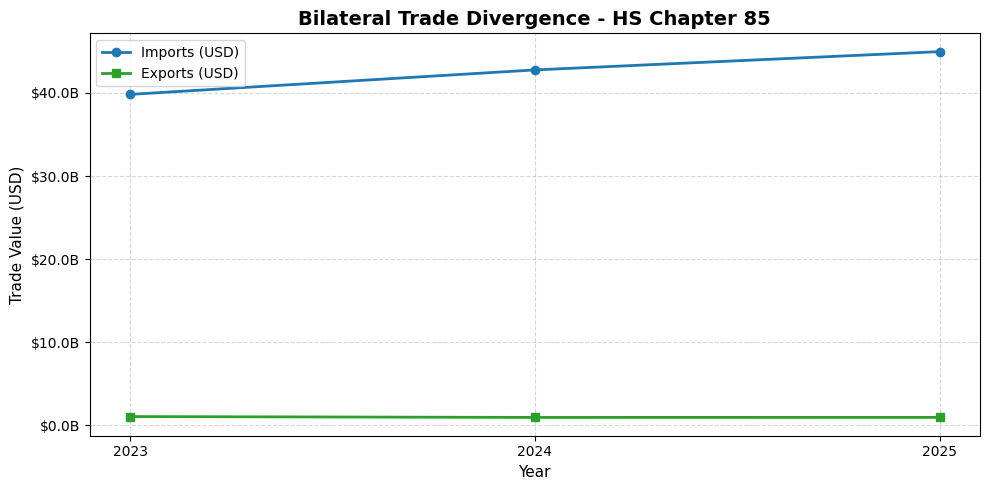

In [74]:
plot_trade_divergence(trade_data, 85)

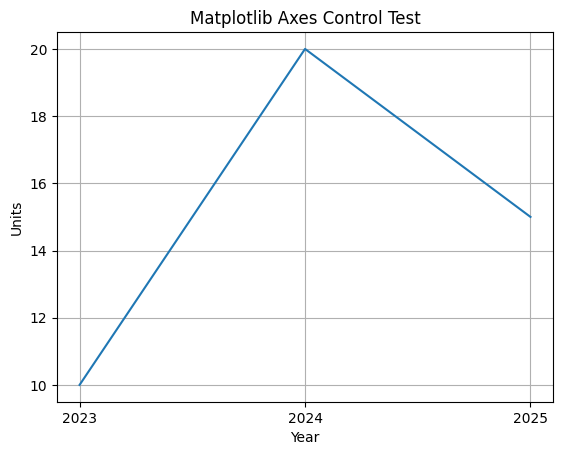

In [75]:
fig, ax = plt.subplots()

ax.plot([2023, 2024, 2025], [10, 20, 15])
ax.set_title('Matplotlib Axes Control Test')
ax.set_xticks([2023, 2024, 2025])
ax.set_xlabel('Year')
ax.set_ylabel('Units')
ax.grid(True)

plt.show()

,chapter,imports_usd,exports_usd,trade_balance_usd,normalized_trade_index
0,85,1.275765e+11,3.007409e+09,-1.245691e+11,-0.9539
1,84,7.370048e+10,1.506250e+09,-7.219423e+10,-0.9599
2,64,2.269195e+09,1.708209e+06,-2.267487e+09,-0.9985



CRITICAL SECTOR DETECTED: HS Chapter 85

=== HISTORICAL METRICS: CHAPTER 85 ===


,chapter,year,imports_usd,exports_usd,trade_balance_usd,asymmetry_ratio,coverage_ratio_pct,normalized_trade_index
0,85,2023,3.982963e+10,1.070976e+09,-3.875865e+10,37.190022,2.69,-0.9476
1,85,2024,4.277251e+10,9.650949e+08,-4.180742e+10,44.319489,2.26,-0.9559
2,85,2025,4.497440e+10,9.713383e+08,-4.400306e+10,46.301481,2.16,-0.9577


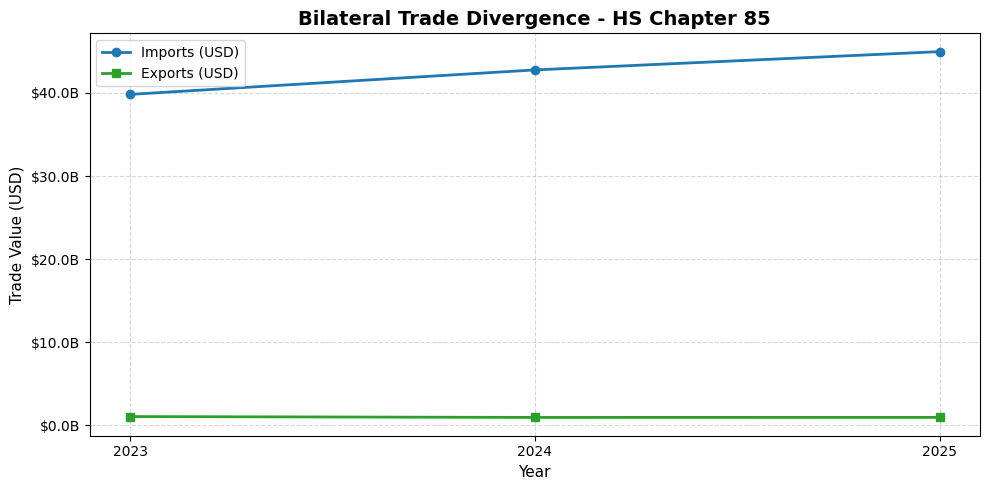

In [76]:
summary = generate_executive_summary(trade_data)
display(summary.head())

critical_chapter = int(summary.iloc[0]['chapter'])
print(f"\nCRITICAL SECTOR DETECTED: HS Chapter {critical_chapter}")

metrics = calculate_trade_metrics(trade_data, critical_chapter)
print(f"\n=== HISTORICAL METRICS: CHAPTER {critical_chapter} ===")
display(metrics)

plot_trade_divergence(trade_data, critical_chapter)